# LR 2.1 – Predicting goal difference at the FIFA World Cup 2026

**Target:** `goal_diff` = Team A goals − Team B goals (104 matches)
**Predictors:** 8 pre-match variables, all expressed as Team A − Team B (see `README.md`).

| Section | What it does |
|---|---|
| 1 | Setup and data loading |
| 2 | Exploratory analysis: target distribution, correlations, multicollinearity (VIF) |
| 3 | OLS on the full data: coefficients, significance, assumption checks |
| 4 | **Competing algorithms** compared with identical repeated 5-fold cross-validation |
| 5 | Statistical test of the differences (corrected resampled t-test) |
| 6 | Chronological validation: train on group stage, test on knockouts |
| 7 | Interpretation figures: coefficients, Lasso path, predicted vs actual |
| 8 | Summary table for the recommendation |

All figures are saved to `../figures/` at 300 dpi for the report.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, HuberRegressor, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Paths work whether the notebook is run from notebooks/ or the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "wc2026_lr21_refined.csv"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

SEED = 42
TARGET = "goal_diff"
FEATURES = ["rank_diff", "elo_diff", "winrate10_diff", "wc_exp_diff",
            "tourn_pts_diff", "host_diff", "rest_diff", "stage"]

# Consistent, colour-blind-checked palette for every figure
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8986"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", "#e34948"])
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.edgecolor": GREY, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})
def save(fig, name):
    fig.savefig(FIG / name)
    print(f"saved figures/{name}")

In [2]:
df = pd.read_csv(DATA, parse_dates=["date"])
X, y = df[FEATURES], df[TARGET]
print(df.shape, "| missing values:", df.isna().sum().sum())
df.head()

(104, 13) | missing values: 0


,match_id,date,team_a,team_b,goal_diff,rank_diff,stage,rest_diff,elo_diff,winrate10_diff,wc_exp_diff,host_diff,tourn_pts_diff
0,1,2026-06-11,Mexico,South Africa,2,46,1,2.0,313.3,0.1,14,1,0
1,2,2026-06-11,South Korea,Czech Republic,1,15,1,1.0,82.9,0.1,10,0,0
2,3,2026-06-12,Canada,Bosnia and Herzegovina,0,34,1,1.0,246.0,0.1,1,1,0
3,4,2026-06-12,United States,Paraguay,3,24,1,-1.0,-92.6,0.1,3,1,0
4,5,2026-06-13,Qatar,Switzerland,0,-37,1,0.0,-394.1,-0.4,-11,0,0


In [3]:
df[[TARGET] + FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
goal_diff,104.0,0.50,2.02,-4.0,-1.00,0.0,2.00,6.0
rank_diff,104.0,7.60,33.55,-76.0,-13.25,6.5,28.50,77.0
elo_diff,104.0,56.42,221.95,-495.5,-107.20,57.5,211.15,557.3
winrate10_diff,104.0,0.05,0.28,-0.7,-0.10,0.1,0.20,0.8
wc_exp_diff,104.0,2.95,8.76,-18.0,-2.25,2.0,10.00,21.0
tourn_pts_diff,104.0,0.44,2.20,-7.0,0.00,0.0,2.00,6.0
host_diff,104.0,0.12,0.36,-1.0,0.00,0.0,0.00,1.0
rest_diff,104.0,0.12,1.48,-7.0,0.00,0.0,1.00,6.0
stage,104.0,1.61,1.16,1.0,1.00,1.0,2.00,7.0


## 2. Exploratory analysis
Goal difference is a whole number, roughly symmetric around a small positive mean (Team A is often the stronger side in FIFA's fixture order).
The heatmap shows which predictors move with the target and which overlap with each other.

saved figures/fig1_eda.png


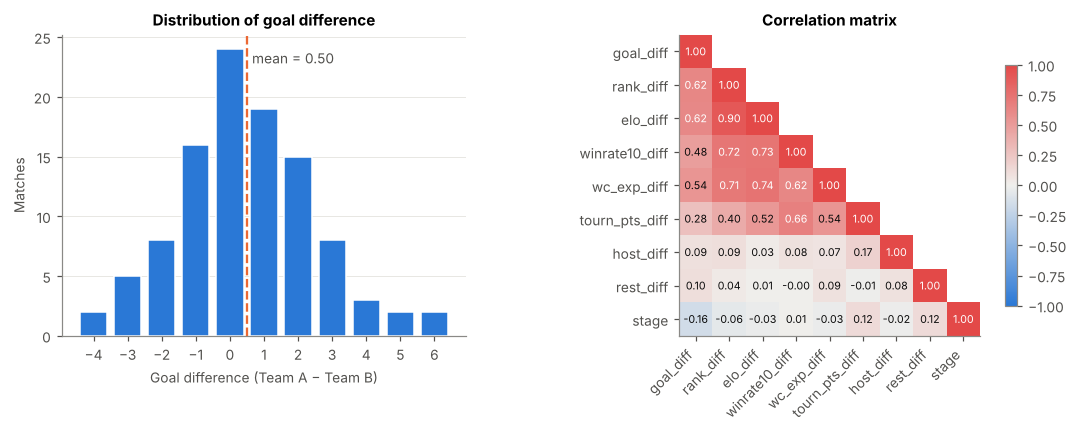

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.25]})

counts = y.value_counts().sort_index()
a1.bar(counts.index, counts.values, color=BLUE, width=0.8, edgecolor="white", linewidth=1)
a1.axvline(y.mean(), color=ORANGE, lw=1.5, ls="--")
a1.text(y.mean() + 0.15, counts.max() * 0.95, f"mean = {y.mean():.2f}", color=INK2)
a1.set(title="Distribution of goal difference", xlabel="Goal difference (Team A − Team B)", ylabel="Matches")
a1.set_xticks(counts.index)
a1.grid(axis="x", visible=False)

corr = df[[TARGET] + FEATURES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = a2.imshow(np.ma.array(corr, mask=mask), cmap=DIVERGING, vmin=-1, vmax=1)
a2.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
a2.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        a2.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK)
a2.grid(False); a2.set_title("Correlation matrix")
fig.colorbar(im, ax=a2, shrink=0.8)
fig.tight_layout(); save(fig, "fig1_eda.png"); plt.show()

In [5]:
# Variance inflation factor: > 5 signals strong multicollinearity
Xs = StandardScaler().fit_transform(X)
vif = pd.Series([variance_inflation_factor(Xs, i) for i in range(Xs.shape[1])], index=FEATURES, name="VIF")
vif.sort_values(ascending=False).round(2).to_frame()

,VIF
elo_diff,7.14
rank_diff,7.08
winrate10_diff,3.23
wc_exp_diff,2.52
tourn_pts_diff,2.36
host_diff,1.10
stage,1.05
rest_diff,1.05


`rank_diff` and `elo_diff` measure team strength in two ways (FIFA points vs Elo), so they are highly correlated.
OLS splits their shared effect unstably, which is exactly the situation regularised models (Ridge, Lasso) are designed for. Section 4 tests whether that matters in practice.

## 3. OLS on the full data – inference and assumptions
Fitted on all 104 matches to read coefficients and p-values. Predictive accuracy is assessed separately in Section 4 (on unseen data).

In [6]:
ols = sm.OLS(y, sm.add_constant(X)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:              goal_diff   R-squared:                       0.440
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     9.333
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           2.03e-09
Time:                        21:31:15   Log-Likelihood:                -190.00
No. Observations:                 104   AIC:                             398.0
Df Residuals:                      95   BIC:                             421.8
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.4676      0.280      1.

In [7]:
# Coefficients rescaled to football-meaningful units
units = {"rank_diff": 10, "elo_diff": 100, "winrate10_diff": 0.1, "wc_exp_diff": 1,
         "tourn_pts_diff": 3, "host_diff": 1, "rest_diff": 1, "stage": 1}
label = {"rank_diff": "+10 FIFA rank places", "elo_diff": "+100 Elo points", "winrate10_diff": "+10 pp win rate",
         "wc_exp_diff": "+1 previous World Cup", "tourn_pts_diff": "+3 tournament points (one win)",
         "host_diff": "host nation", "rest_diff": "+1 rest day", "stage": "one stage later"}
interp = pd.DataFrame({
    "change in predictor": [label[f] for f in FEATURES],
    "effect on goal diff": [ols.params[f] * units[f] for f in FEATURES],
    "p-value": ols.pvalues[FEATURES].values,
}, index=FEATURES).round(3)
interp

,change in predictor,effect on goal diff,p-value
rank_diff,+10 FIFA rank places,0.118,0.340
elo_diff,+100 Elo points,0.290,0.123
winrate10_diff,+10 pp win rate,0.038,0.705
wc_exp_diff,+1 previous World Cup,0.037,0.190
tourn_pts_diff,+3 tournament points (one win),-0.221,0.498
host_diff,host nation,0.266,0.555
rest_diff,+1 rest day,0.119,0.270
stage,one stage later,-0.227,0.101


saved figures/fig2_ols_diagnostics.png


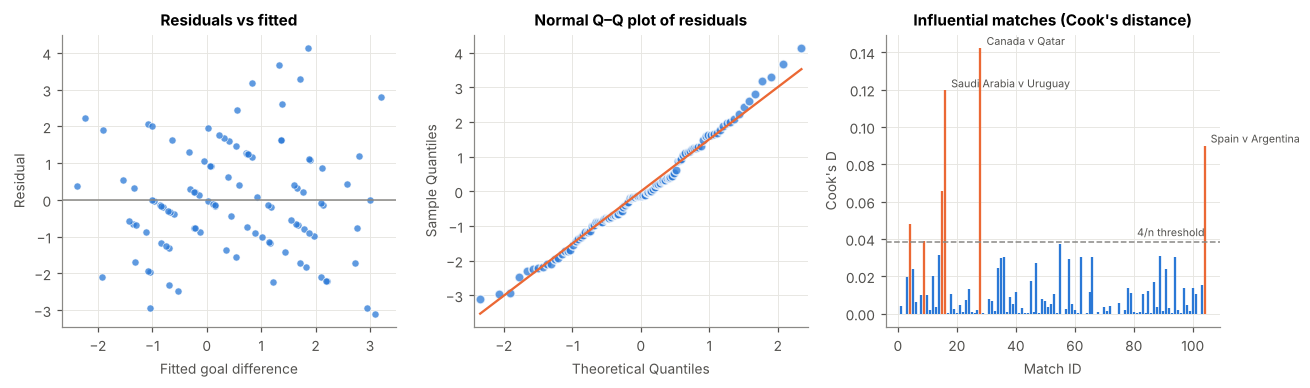

Breusch–Pagan (constant variance)  p = 0.211
Shapiro–Wilk (normal residuals)    p = 0.423
Durbin–Watson (independence)      DW = 2.08  (≈2 is good)
Matches with Cook's D > 4/n: 6


In [8]:
resid, fitted = ols.resid, ols.fittedvalues
infl = ols.get_influence()
cooks = infl.cooks_distance[0]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].scatter(fitted, resid, s=22, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5)
ax[0].axhline(0, color=GREY, lw=1)
ax[0].set(title="Residuals vs fitted", xlabel="Fitted goal difference", ylabel="Residual")

sm.qqplot(resid, line="s", ax=ax[1], markerfacecolor=BLUE, markeredgecolor="white", alpha=0.75)
ax[1].get_lines()[1].set_color(ORANGE)
ax[1].set_title("Normal Q–Q plot of residuals")

thr = 4 / len(df)
ax[2].vlines(df.match_id, 0, cooks, color=np.where(cooks > thr, ORANGE, BLUE), lw=1.5)
ax[2].axhline(thr, color=GREY, ls="--", lw=1); ax[2].text(df.match_id.max(), thr * 1.08, "4/n threshold", color=INK2, ha="right", fontsize=7)
for i in np.argsort(cooks)[-3:]:
    ax[2].annotate(f"{df.team_a[i]} v {df.team_b[i]}", (df.match_id[i], cooks[i]), fontsize=7,
                   xytext=(4, 2), textcoords="offset points", color=INK2)
ax[2].set(title="Influential matches (Cook's distance)", xlabel="Match ID", ylabel="Cook's D")
fig.tight_layout(); save(fig, "fig2_ols_diagnostics.png"); plt.show()

bp = het_breuschpagan(resid, sm.add_constant(X))
print(f"Breusch–Pagan (constant variance)  p = {bp[1]:.3f}")
print(f"Shapiro–Wilk (normal residuals)    p = {stats.shapiro(resid).pvalue:.3f}")
print(f"Durbin–Watson (independence)      DW = {durbin_watson(resid):.2f}  (≈2 is good)")
print(f"Matches with Cook's D > 4/n: {(cooks > thr).sum()}")

## 4. Competing algorithms – systematic comparison
Every model is evaluated on **exactly the same 50 train/test splits** (5-fold CV repeated 10 times, seed 42), which makes the comparison fair and paired.

| Model | Why it is included |
|---|---|
| Baseline (mean) | Any useful model must beat "always predict the average" |
| OLS | Standard, fully interpretable linear regression |
| Ridge | Shrinks coefficients – handles the correlated strength variables |
| Lasso | Shrinks and can set coefficients to zero – automatic variable selection |
| Huber | Robust linear regression – down-weights blow-out results (e.g. 7–1) |
| Random Forest | Non-linear benchmark – tests whether a linear form is too simple |

**Leakage control:** scaling is fitted inside each training fold (pipeline), and Ridge/Lasso choose their penalty with an *inner* CV on the training fold only (nested CV).

**Metrics:** MAE and RMSE (in goals, lower is better), R², and *outcome accuracy* – how often the predicted result (win / draw / loss, where |prediction| < 0.5 counts as a draw) matches the real one.

In [9]:
ALPHAS = np.logspace(-3, 3, 50)
models = {
    "Baseline (mean)": DummyRegressor(),
    "OLS":             LinearRegression(),
    "Ridge":           RidgeCV(alphas=ALPHAS),
    "Lasso":           LassoCV(alphas=ALPHAS, cv=5, max_iter=50_000),
    "Huber":           HuberRegressor(max_iter=2_000),
    "Random Forest":   RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}
pipes = {name: make_pipeline(StandardScaler(), m) for name, m in models.items()}

def outcome(v):
    return np.where(v > 0.5, 1, np.where(v < -0.5, -1, 0))

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
rows = []
for fold, (tr, te) in enumerate(cv.split(X)):
    for name, pipe in pipes.items():
        p = clone(pipe).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
        yt = y.iloc[te]
        rows.append({"fold": fold, "model": name,
                     "MAE": mean_absolute_error(yt, p),
                     "RMSE": mean_squared_error(yt, p) ** 0.5,
                     "R2": r2_score(yt, p),
                     "Outcome acc": (outcome(p) == np.sign(yt)).mean()})
cv_res = pd.DataFrame(rows)

summary = (cv_res.groupby("model")[["MAE", "RMSE", "R2", "Outcome acc"]]
                 .agg(["mean", "std"]).sort_values(("MAE", "mean")))
summary.round(3)

MAE          RMSE            R2        Outcome acc       
                  mean    std   mean    std   mean    std        mean    std
model                                                                       
Ridge            1.299  0.222  1.615  0.267  0.300  0.146       0.614  0.081
Lasso            1.320  0.233  1.635  0.277  0.280  0.171       0.586  0.098
Random Forest    1.340  0.215  1.676  0.249  0.225  0.246       0.656  0.089
OLS              1.345  0.234  1.679  0.269  0.232  0.213       0.616  0.089
Huber            1.369  0.240  1.709  0.273  0.209  0.192       0.602  0.089
Baseline (mean)  1.606  0.242  2.013  0.299 -0.077  0.102       0.301  0.126

saved figures/fig3_cv_comparison.png


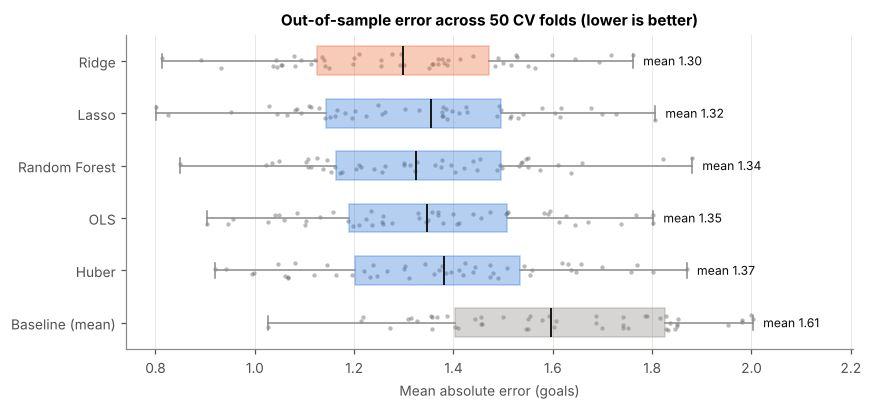

In [10]:
order = summary.index.tolist()
best = order[0]
fig, ax = plt.subplots(figsize=(8, 3.8))
data = [cv_res.loc[cv_res.model == m, "MAE"] for m in order]
bp_ = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                 medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=GREY), capprops=dict(color=GREY))
for patch, m in zip(bp_["boxes"], order):
    c = ORANGE if m == best else GREY if m.startswith("Baseline") else BLUE
    patch.set(facecolor=c, alpha=0.35, edgecolor=c)
rng = np.random.default_rng(SEED)
for i, d in enumerate(data, start=1):
    ax.scatter(d, i + rng.uniform(-0.15, 0.15, len(d)), s=8, color=INK2, alpha=0.4, linewidth=0)
    ax.text(d.max() + 0.02, i, f"mean {d.mean():.2f}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(1, len(order) + 1), order); ax.invert_yaxis()
ax.set_xlim(right=cv_res.MAE.max() + 0.2)
ax.set(title="Out-of-sample error across 50 CV folds (lower is better)", xlabel="Mean absolute error (goals)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "fig3_cv_comparison.png"); plt.show()

## 5. Are the differences statistically significant?
A plain paired t-test across CV folds is **over-confident**: the folds share most of their training data, so their errors are not independent.
We therefore use the **corrected resampled t-test** (Nadeau & Bengio, 2003), which inflates the variance by the factor (1/k + n_test/n_train). The naive p-value is shown for contrast.

In [11]:
def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=k - 1)

n_test = len(df) // 5
n_train = len(df) - n_test
mae = cv_res.pivot(index="fold", columns="model", values="MAE")
tests = []
for m in order[1:]:
    t, p = corrected_ttest(mae[m], mae[best], n_train, n_test)
    tests.append({"compared with": best, "model": m,
                  "MAE difference": mae[m].mean() - mae[best].mean(),
                  "corrected p": p, "naive paired p": stats.ttest_rel(mae[m], mae[best]).pvalue})
pd.DataFrame(tests).round(4)

,compared with,model,MAE difference,corrected p,naive paired p
0,Ridge,Lasso,0.0205,0.3998,0.0037
1,Ridge,Random Forest,0.0405,0.5607,0.0405
2,Ridge,OLS,0.0460,0.2065,0.0000
3,Ridge,Huber,0.0697,0.0510,0.0000
4,Ridge,Baseline (mean),0.3064,0.0011,0.0000


## 6. Chronological validation – a realistic forecasting test
Random CV mixes early and late matches. Here every model is trained **only on the 72 group-stage matches** and tested on the **32 knockout matches**, exactly as a forecaster would have to do during the tournament.
Knockout matches are usually closer (stronger teams, more caution), so this is a harder test.

In [12]:
is_group = df.stage == 1
Xtr, ytr, Xte, yte = X[is_group], y[is_group], X[~is_group], y[~is_group]
chrono = []
for name, pipe in pipes.items():
    p = clone(pipe).fit(Xtr, ytr).predict(Xte)
    chrono.append({"model": name, "MAE": mean_absolute_error(yte, p),
                   "RMSE": mean_squared_error(yte, p) ** 0.5,
                   "Outcome acc": (outcome(p) == np.sign(yte)).mean()})
chrono = pd.DataFrame(chrono).set_index("model").sort_values("MAE")
print("Note: `stage` is constant (=1) in the training set, so models cannot learn its effect here.")
chrono.round(3)

Note: `stage` is constant (=1) in the training set, so models cannot learn its effect here.


,MAE,RMSE,Outcome acc
model,,,
Ridge,1.122,1.449,0.594
Lasso,1.138,1.432,0.594
OLS,1.183,1.501,0.531
Huber,1.192,1.513,0.562
Random Forest,1.214,1.514,0.594
Baseline (mean),1.344,1.627,0.500


## 7. Interpretation figures
**7a – How regularisation changes the coefficients.** Coefficients are standardised (effect of a one-standard-deviation change) so they can be compared across variables. OLS is shown with its 95% confidence interval.

saved figures/fig4_coefficients.png


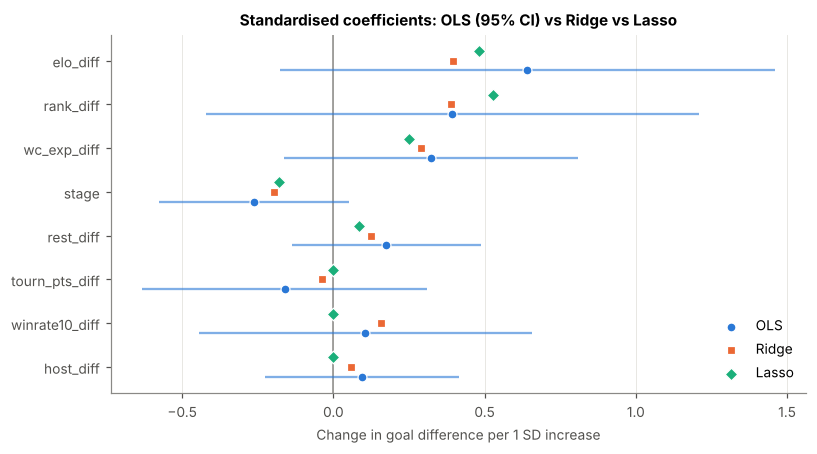

Ridge alpha = 45 | Lasso alpha = 0.091 | Lasso kept 5 of 8 variables


In [13]:
Xz = pd.DataFrame(StandardScaler().fit_transform(X), columns=FEATURES)
ols_z = sm.OLS(y, sm.add_constant(Xz)).fit()
ridge = RidgeCV(alphas=ALPHAS).fit(Xz, y)
lasso = LassoCV(alphas=ALPHAS, cv=KFold(5, shuffle=True, random_state=SEED), max_iter=50_000).fit(Xz, y)
coefs = pd.DataFrame({"OLS": ols_z.params[FEATURES], "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=FEATURES)
ci = ols_z.conf_int().loc[FEATURES]
feat_order = coefs["OLS"].abs().sort_values().index

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ypos = np.arange(len(feat_order))
ax.axvline(0, color=GREY, lw=1)
ax.hlines(ypos - 0.22, ci.loc[feat_order, 0], ci.loc[feat_order, 1], color=BLUE, lw=1.5, alpha=0.6)
for off, (name, c, mk) in zip([-0.22, 0, 0.22], [("OLS", BLUE, "o"), ("Ridge", ORANGE, "s"), ("Lasso", AQUA, "D")]):
    ax.scatter(coefs.loc[feat_order, name], ypos + off, color=c, marker=mk, s=34, label=name,
               edgecolor="white", linewidth=0.8, zorder=3)
ax.set_yticks(ypos, feat_order)
ax.set(title="Standardised coefficients: OLS (95% CI) vs Ridge vs Lasso",
       xlabel="Change in goal difference per 1 SD increase")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "fig4_coefficients.png"); plt.show()
print(f"Ridge alpha = {ridge.alpha_:.3g} | Lasso alpha = {lasso.alpha_:.3g} | "
      f"Lasso kept {np.sum(lasso.coef_ != 0)} of {len(FEATURES)} variables")

**7b – Lasso path.** As the penalty grows (right to left), weaker variables are forced to zero first – a visual ranking of variable importance.

saved figures/fig5_lasso_path.png


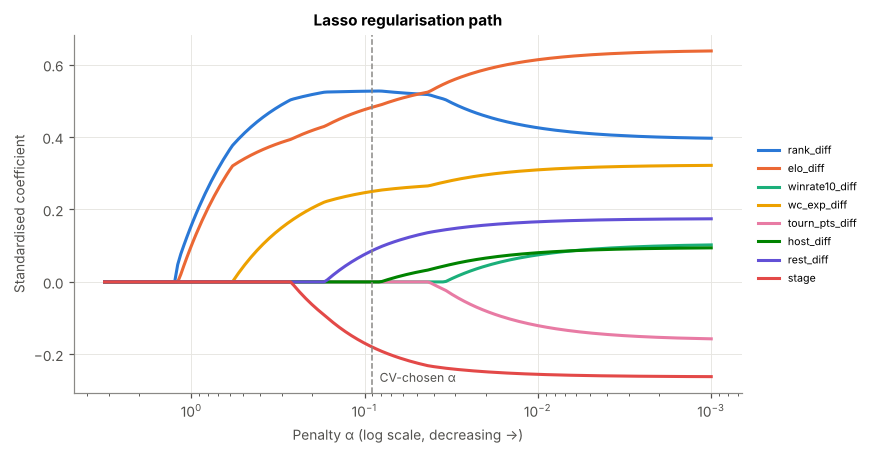

In [14]:
alphas_p, path, _ = lasso_path(Xz.values, (y - y.mean()).values, alphas=np.logspace(-3, 0.5, 200))
PAL8 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, f in enumerate(FEATURES):
    ax.plot(alphas_p, path[i], color=PAL8[i], lw=2, label=f)
ax.axvline(lasso.alpha_, color=GREY, ls="--", lw=1)
ax.text(lasso.alpha_ * 0.9, ax.get_ylim()[0] * 0.9, "CV-chosen α", color=INK2, fontsize=8)
ax.set_xscale("log"); ax.invert_xaxis()
ax.set(title="Lasso regularisation path", xlabel="Penalty α (log scale, decreasing →)", ylabel="Standardised coefficient")
ax.legend(frameon=False, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout(); save(fig, "fig5_lasso_path.png"); plt.show()

**7c – Where the model succeeds and fails.** Out-of-sample predictions (each match predicted by a model that never saw it) against the real result. The largest misses are labelled – these are the tournament's biggest surprises relative to pre-match information.

saved figures/fig6_pred_vs_actual.png


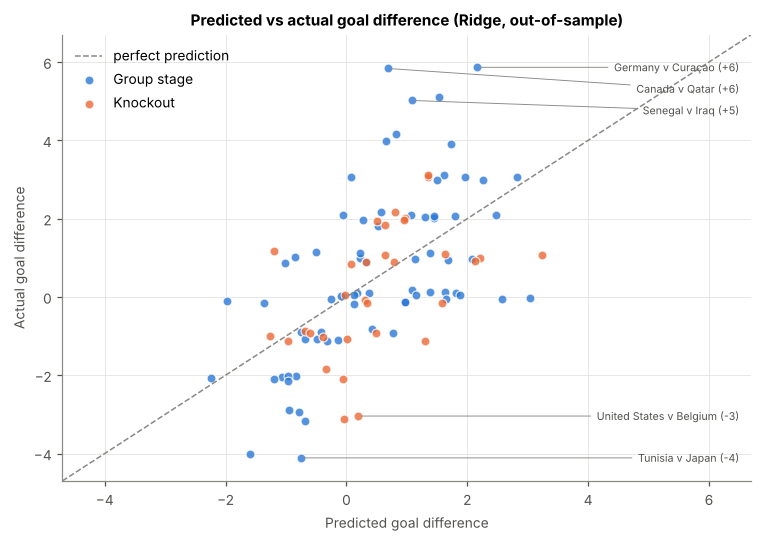

Ridge: out-of-sample MAE = 1.318, outcome accuracy = 61.5%


In [15]:
linear = [m for m in order if m in ("OLS", "Ridge", "Lasso", "Huber")]
chosen = linear[0]                       # best-performing linear model in Section 4
oof = cross_val_predict(pipes[chosen], X, y, cv=KFold(5, shuffle=True, random_state=SEED))
err = y - oof
rng = np.random.default_rng(SEED)
jit = y + rng.uniform(-0.18, 0.18, len(y))

fig, ax = plt.subplots(figsize=(7, 5))
lim = (min(oof.min(), y.min()) - 0.7, max(oof.max(), y.max()) + 0.7)
ax.plot(lim, lim, color=GREY, ls="--", lw=1, label="perfect prediction")
for grp, c, lab in [(True, BLUE, "Group stage"), (False, ORANGE, "Knockout")]:
    s = is_group == grp
    ax.scatter(oof[s], jit[s], s=34, color=c, alpha=0.8, edgecolor="white", linewidth=0.8, label=lab)
# label the 3 biggest positive surprises and 2 biggest negative ones in a tidy column
picks = [err.sort_values().index[-3:][::-1], err.sort_values().index[:2]]
for grp in picks:
    grp = sorted(grp, key=lambda i: -jit[i])
    ty = None
    for i in grp:
        ty = jit[i] if ty is None else min(jit[i], ty - 0.55)
        ax.annotate(f"{df.team_a[i]} v {df.team_b[i]} ({'+' if y[i] > 0 else ''}{y[i]})",
                    xy=(oof[i], jit[i]), xytext=(lim[1] - 0.2, ty), ha="right", va="center", fontsize=7,
                    color=INK2, arrowprops=dict(arrowstyle="-", color=GREY, lw=0.6))
ax.set(xlim=lim, ylim=lim, title=f"Predicted vs actual goal difference ({chosen}, out-of-sample)",
       xlabel="Predicted goal difference", ylabel="Actual goal difference")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); save(fig, "fig6_pred_vs_actual.png"); plt.show()
print(f"{chosen}: out-of-sample MAE = {mean_absolute_error(y, oof):.3f}, "
      f"outcome accuracy = {(outcome(oof) == np.sign(y)).mean():.1%}")

## 8. Summary for the recommendation

In [16]:
final = pd.DataFrame({
    "CV MAE": summary[("MAE", "mean")],
    "CV MAE sd": summary[("MAE", "std")],
    "CV R2": summary[("R2", "mean")],
    "CV outcome acc": summary[("Outcome acc", "mean")],
    "Knockout-test MAE": chrono["MAE"],
}).loc[order].round(3)
final.to_csv(ROOT / "figures" / "table_model_comparison.csv")
final

,CV MAE,CV MAE sd,CV R2,CV outcome acc,Knockout-test MAE
model,,,,,
Ridge,1.299,0.222,0.300,0.614,1.122
Lasso,1.320,0.233,0.280,0.586,1.138
Random Forest,1.340,0.215,0.225,0.656,1.214
OLS,1.345,0.234,0.232,0.616,1.183
Huber,1.369,0.240,0.209,0.602,1.192
Baseline (mean),1.606,0.242,-0.077,0.301,1.344


**Writing the recommendation (in your own words, in the report).** Weigh up:
- **Accuracy** – CV MAE and the knockout-test MAE (Sections 4 and 6)
- **Whether the gap is real** – corrected p-values (Section 5); a non-significant gap means the simpler model is defensible
- **Stability** – the spread across folds (Figure 3)
- **Interpretability** – OLS and Ridge give one clear coefficient per variable; Random Forest does not
- **Practicality** – which model a match analyst could actually explain and use